# School-site suitability mapping: TA Chimaliro, Thyolo

This notebook downloads data, prepares layers, applies the assignment criteria and creates static/interactive maps. **Verify the boundary name and district before accepting any result.**

In [19]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import folium
import requests
from shapely.geometry import box
import os
import warnings
warnings.filterwarnings('ignore')


# Define paths
BASE_DIR = os.path.abspath("..")
DATA_DIR = os.path.join(BASE_DIR, "data")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")

print("Setup complete. Working directories established.")

Setup complete. Working directories established.


## 1. Retrieve and verify the TA boundary and other datasets


In [26]:
# Define paths
DATA = "C:/Users/HP/Documents/chimaliro-school-site-accessibility/data"
ta_path = f"{DATA}/mw_ta.geojson"
small_roads_path = f"{DATA}/thyolo_roads.geojson"

# 1. Load the TA boundary and filter for Chimaliro
print("Loading TA boundary...")
ta_raw = gpd.read_file(ta_path)
name_col = "TA_NAME" 
ta = ta_raw[ta_raw[name_col].astype(str).str.upper().str.contains("CHIMALIRO", na=False)].copy()
print(f"Found {len(ta)} TA feature(s) for Chimaliro.")

# 2. Load remaining datasets
print("\nLoading datasets and fixing CRS...")
prot_raw    = gpd.read_file(f"{DATA}/mw_protected_areas.geojson")
roads_small = gpd.read_file(small_roads_path) 
sch_raw     = gpd.read_file(f"{DATA}/mw_primary_schools.geojson")

# 3. REPROJECT EVERYTHING TO EPSG:32736 AND CLIP TO CHIMALIRO
# We do this so the distance analysis (buffers) works in METERS.
UTM_CRS = "EPSG:32736"

# TA is already the correct area, just ensure CRS
ta = ta.to_crs(UTM_CRS)

# Protected areas: Reproject to UTM, then clip to TA
prot_ta = gpd.clip(prot_raw.to_crs(UTM_CRS), ta)

# Roads: Reproject to UTM (they are already clipped to Chimaliro)
roads_ta = roads_small.to_crs(UTM_CRS)

# Schools: Reproject to UTM, then clip to TA to keep only schools in Chimaliro
schools_ta = gpd.clip(sch_raw.to_crs(UTM_CRS), ta)

# 4. Inspect the cleaned data
print("\n--- Cleaned Data Check ---")
for name, gdf in [("TA", ta), ("Protected", prot_ta),
                  ("Roads", roads_ta), ("Schools", schools_ta)]:
    print(f"{name:10s} | CRS: {gdf.crs} | rows: {len(gdf)}")

Loading TA boundary...
Found 1 TA feature(s) for Chimaliro.

Loading datasets and fixing CRS...

--- Cleaned Data Check ---
TA         | CRS: EPSG:32736 | rows: 1
Protected  | CRS: EPSG:32736 | rows: 0
Roads      | CRS: EPSG:32736 | rows: 409
Schools    | CRS: EPSG:32736 | rows: 29


### Select the Chimaliro feature
The selection below is deliberately strict. Inspect the candidate row and verify its district. If there is no unambiguous match, stop and use a verified boundary dataset.

In [11]:
# Filter TA Chimaliro
# Inspect the TA layer to find the correct name column
print(ta_raw.columns.tolist())
print(ta_raw.head())

# Adjust column/value to match your actual file
name_col = "TA_NAME" if "TA_NAME" in ta_raw.columns else [c for c in ta_raw.columns if "name" in c.lower()][0]
print(ta_raw[name_col].unique())

ta = ta_raw[ta_raw[name_col].str.upper().str.contains("CHIMALIRO", na=False)].copy()
print("Chimaliro features:", len(ta))

['AREA', 'PERIMETER', 'MW_DIST_BN', 'MW_DIST__1', 'TA_NAME', 'geometry']
          AREA   PERIMETER  MW_DIST_BN  MW_DIST__1      TA_NAME  \
0  435789088.0  121972.047           2           1       Kameme   
1  976046528.0  187509.094           3           2  Mwabulambya   
2  658186880.0  151400.891           4           3  Mwenemisiku   
3  585887296.0  142679.516           5           4    Mwakaboko   
4  741488832.0  156017.750           7           6   Mwenewenya   

                                            geometry  
0  MULTIPOLYGON (((494179.875 8954428, 494109.562...  
1  MULTIPOLYGON (((518427.906 8950685, 518462.562...  
2  MULTIPOLYGON (((567154.375 8939596, 567191 893...  
3  MULTIPOLYGON (((570334.938 8938795, 570384.875...  
4  MULTIPOLYGON (((556544.562 8910530, 556500.812...  
['Kameme' 'Mwabulambya' 'Mwenemisiku' 'Mwakaboko' 'Mwenewenya'
 "Mwirang'ombe" 'Wasambo' 'Nyika Plateau' 'Mwalweni' 'Kachulu' 'Katumbi'
 'Mwamulowe' 'Mwankhunikira' 'Mwahenga' 'Chapinduka' 'Jara

## 2. Reproject everything to a projected CRS (UTM Zone 36S, covers Malawi)
Road classes are defined here as motorway, trunk, primary, secondary and tertiary, including links. School features are filtered for primary-school tags. Protected-area tags in OSM may be incomplete and must be checked against an authoritative inventory where possible.

In [12]:
# Reproject everything to a projected CRS (UTM Zone 36S, covers Malawi)
UTM = "EPSG:32736"   # WGS84 / UTM 36S

ta      = ta.to_crs(UTM)
prot    = prot_raw.to_crs(UTM)
roads   = roads_raw.to_crs(UTM)
schools = sch_raw.to_crs(UTM)

# Clip features to TA boundary
prot_ta    = gpd.clip(prot, ta)
roads_ta   = gpd.clip(roads, ta)
schools_ta = gpd.clip(schools, ta)

print("Features inside Chimaliro:")
print(f"  Protected areas: {len(prot_ta)}")
print(f"  Roads:           {len(roads_ta)}")
print(f"  Schools:         {len(schools_ta)}")

Features inside Chimaliro:
  Protected areas: 0
  Roads:           409
  Schools:         29


## 3. Record data metadata

In [13]:
#Clean data (drop invalid/empty geometries, fix geometry types)
def clean(gdf):
    gdf = gdf[gdf.geometry.notnull()].copy()
    gdf = gdf[~gdf.geometry.is_empty]
    gdf = gdf[gdf.geometry.is_valid]
    return gdf

ta      = clean(ta)
prot_ta = clean(prot_ta)
roads_ta= clean(roads_ta)
schools_ta = clean(schools_ta)
print("Cleaned shapes:", len(ta), len(prot_ta), len(roads_ta), len(schools_ta))

Cleaned shapes: 1 0 409 29


## 4. Apply the three criteria
Exclude areas within 2,000 m of existing primary schools, retain areas within 500 m of main roads, subtract mapped protected areas, and clip to the TA boundary. Distances are in metres because all layers are projected to EPSG:32736.

In [14]:
#Criterion 1: buffer existing schools by 2 km, then EXCLUDE
schools_buf = schools_ta.buffer(2000)          # 2 km exclusion zone
schools_buf_gdf = gpd.GeoDataFrame(geometry=schools_buf, crs=UTM)
print("Total school exclusion area (km²):",
      round(schools_buf_gdf.area.sum() / 1e6, 2))

# Criterion 2: 500 m buffer AROUND main roads (allowed zone)
roads_buf = roads_ta.buffer(500)               # 500 m walkable-to-road band
roads_buf_gdf = gpd.GeoDataFrame(geometry=roads_buf, crs=UTM)
print("Total road-access area (km²):",
      round(roads_buf_gdf.area.sum() / 1e6, 2))

#Combine criteria with overlay
# Step A: area within TA and within 500 m of road
candidate = gpd.overlay(ta[["geometry"]], roads_buf_gdf, how="intersection")

# Step B: remove 2 km school exclusion zones
candidate = gpd.overlay(candidate, schools_buf_gdf, how="difference")

# Step C: remove protected areas
suitable = gpd.overlay(candidate, prot_ta[["geometry"]], how="difference")

# Step D: dissolve into a single layer
suitable = suitable.dissolve().reset_index(drop=True)
suitable["area_km2"] = suitable.area / 1e6
print(suitable[["area_km2"]])
print("TOTAL SUITABLE AREA (km²):", round(suitable["area_km2"].sum(), 2))

Total school exclusion area (km²): 363.84
Total road-access area (km²): 659.94
    area_km2
0  43.092401
TOTAL SUITABLE AREA (km²): 43.09


In [15]:
# Save GeoJSON for the interactive map
os.makedirs("C:/Users/HP/Documents/chimaliro-school-site-accessibility/outputs", exist_ok=True)
suitable.to_file("C:/Users/HP/Documents/chimaliro-school-site-accessibility/outputs/suitable_areas.geojson", driver="GeoJSON")

## 5. Static map

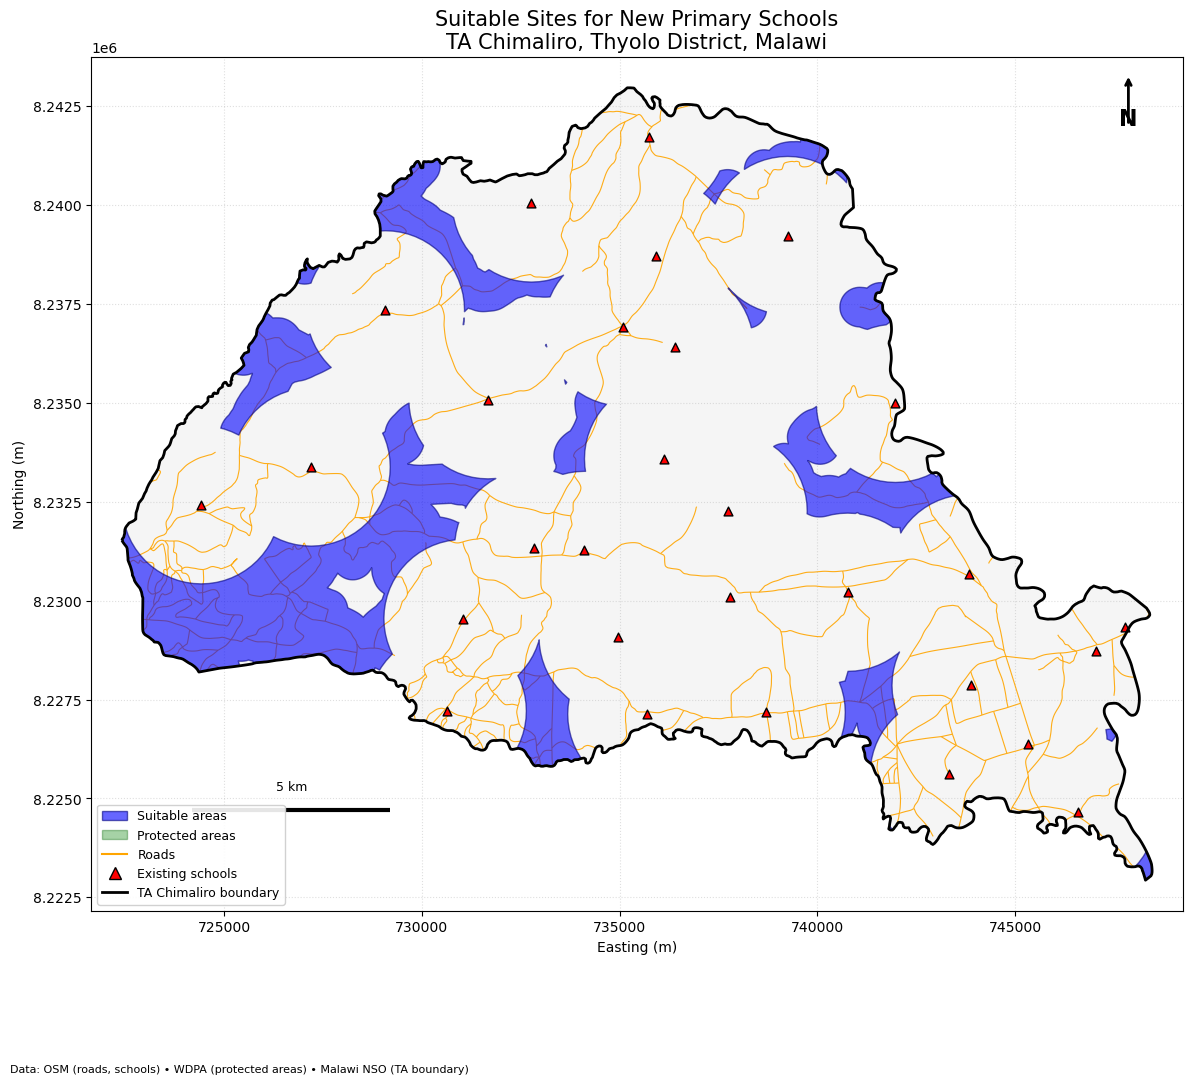

In [23]:
# Create the figure and axis
fig, ax = plt.subplots(figsize=(12, 12))

# 1. Plot the layers (removed label= to avoid conflicts)
ta.plot(ax=ax, color="whitesmoke", edgecolor="none", zorder=0) # Background
prot_ta.plot(ax=ax, color="green", alpha=0.35, edgecolor="darkgreen", zorder=1)
roads_ta.plot(ax=ax, color="orange", linewidth=0.8, alpha=0.9, zorder=2)
suitable.plot(ax=ax, color="blue", alpha=0.6, edgecolor="navy", zorder=3)
schools_ta.plot(ax=ax, color="red", marker="^", markersize=40, edgecolor="black", zorder=4)
ta.boundary.plot(ax=ax, color="black", linewidth=2, zorder=5)

# 2. Zoom to TA boundaries
minx, miny, maxx, maxy = ta.total_bounds
pad = 0.03 * max(maxx - minx, maxy - miny)
ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)

# 3. Create custom legend handles (This fixes your issue)
handles = [
    mpatches.Patch(facecolor="blue", edgecolor="navy", alpha=0.6, label="Suitable areas"),
    mpatches.Patch(facecolor="green", edgecolor="darkgreen", alpha=0.35, label="Protected areas"),
    mlines.Line2D([], [], color="orange", linewidth=1.5, label="Roads"),
    mlines.Line2D([], [], color="red", marker="^", markersize=9, 
                  linestyle="None", markeredgecolor="black", label="Existing schools"),
    mlines.Line2D([], [], color="black", linewidth=2, label="TA Chimaliro boundary"),
]

# Add the custom legend
ax.legend(handles=handles, loc="lower left", fontsize=9, framealpha=0.9)

# 4. Formatting
ax.set_title("Suitable Sites for New Primary Schools\nTA Chimaliro, Thyolo District, Malawi", fontsize=15)
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
ax.grid(True, linestyle=":", alpha=0.4)

# 5. Scale bar (5 km)
x0, y0 = minx + pad + 1000, miny + pad + 1000
ax.plot([x0, x0 + 5000], [y0, y0], color="black", linewidth=3, solid_capstyle="butt")
ax.text(x0 + 2500, y0 + 500, "5 km", ha="center", fontsize=9)

# 6. North arrow
ax.annotate("N", xy=(0.95, 0.92), xycoords="axes fraction", ha="center", fontsize=16, fontweight="bold")
ax.annotate("", xy=(0.95, 0.98), xytext=(0.95, 0.92), xycoords="axes fraction", arrowprops=dict(arrowstyle="->", lw=2))

# 7. Source attribution
fig.text(0.01, 0.01, "Data: OSM (roads, schools) • WDPA (protected areas) • Malawi NSO (TA boundary)", fontsize=8)

plt.tight_layout()
plt.savefig("C:/Users/HP/Documents/chimaliro-school-site-accessibility/outputs/suitable_areas_map.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Interactive map with layer controls and popups

In [17]:
# Interactive folium map (saved HTML)
# Convert back to WGS84 for web mapping
ta_wgs      = ta.to_crs(4326)
prot_wgs    = prot_ta.to_crs(4326)
roads_wgs   = roads_ta.to_crs(4326)
sch_wgs     = schools_ta.to_crs(4326)
suit_wgs    = suitable.to_crs(4326)

c = ta_wgs.geometry.centroid.iloc[0]
m = folium.Map(location=[c.y, c.x], zoom_start=11, tiles="OpenStreetMap")

# Suitable areas
folium.GeoJson(
    suit_wgs,
    name="Suitable areas",
    style_function=lambda f: {"fillColor": "blue", "color": "navy", "fillOpacity": 0.6},
    tooltip=folium.GeoJsonTooltip(fields=["area_km2"], aliases=["Area (km²):"]),
).add_to(m)

folium.GeoJson(prot_wgs, name="Protected areas",
               style_function=lambda f: {"fillColor": "green", "color": "darkgreen",
                                          "fillOpacity": 0.35}).add_to(m)
folium.GeoJson(roads_wgs, name="Roads",
               style_function=lambda f: {"color": "orange", "weight": 2}).add_to(m)
folium.GeoJson(ta_wgs, name="TA boundary",
               style_function=lambda f: {"color": "black", "weight": 3,
                                          "fillOpacity": 0}).add_to(m)

for _, r in sch_wgs.iterrows():
    folium.CircleMarker(location=[r.geometry.y, r.geometry.x],
                        radius=5, color="red", fill=True,
                        popup="Existing primary school").add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.save("C:/Users/HP/Documents/chimaliro-school-site-accessibility/outputs/interactive_map.html")

In [21]:
# 1. Convert all layers to WGS84 (EPSG:4326) for web mapping
ta_wgs      = ta.to_crs(4326)
prot_wgs    = prot_ta.to_crs(4326)
roads_wgs   = roads_ta.to_crs(4326)
sch_wgs     = schools_ta.to_crs(4326)
suit_wgs    = suitable.to_crs(4326)

# Calculate centroid of TA for map center
c = ta_wgs.geometry.unary_union.centroid
m = folium.Map(location=[c.y, c.x], zoom_start=11, tiles="Esri WorldStreetMap")
#m = folium.Map(location=[c.y, c.x], zoom_start=11, tiles="OpenStreetMap")

# 2. Define style functions OUTSIDE the map builder (prevents closure bugs)
def style_suitable(f):
    return {"fillColor": "blue", "color": "navy", "weight": 1, "fillOpacity": 0.6}

def style_protected(f):
    return {"fillColor": "green", "color": "darkgreen", "weight": 1, "fillOpacity": 0.35}

def style_roads(f):
    return {"color": "orange", "weight": 2, "opacity": 0.8}

def style_ta(f):
    return {"color": "black", "weight": 3, "fillOpacity": 0}

# 3. Add layers to the map
# Suitable Areas
folium.GeoJson(
    suit_wgs,
    name="Suitable areas",
    style_function=style_suitable,
    tooltip=folium.GeoJsonTooltip(fields=["area_km2"], aliases=["Area (km²):"])
).add_to(m)

# Protected Areas
folium.GeoJson(
    prot_wgs, 
    name="Protected areas",
    style_function=style_protected
).add_to(m)

# Roads
folium.GeoJson(
    roads_wgs, 
    name="Roads",
    style_function=style_roads
).add_to(m)

# TA Boundary (drawn last to stay on top)
folium.GeoJson(
    ta_wgs, 
    name="TA Chimaliro boundary",
    style_function=style_ta
).add_to(m)

# 4. Add schools as Circle Markers inside a FeatureGroup (so it toggles properly)
schools_layer = folium.FeatureGroup(name="Existing primary schools")
for _, r in sch_wgs.iterrows():
    folium.CircleMarker(
        location=[r.geometry.y, r.geometry.x],
        radius=5, 
        color="red", 
        fill=True,
        fill_color="red",
        fill_opacity=1.0,
        popup="Existing primary school"
    ).add_to(schools_layer)
schools_layer.add_to(m)

# 5. Add the Layer Control (Legend)
folium.LayerControl(collapsed=False).add_to(m)

# 6. Save the map
m.save("C:/Users/HP/Documents/chimaliro-school-site-accessibility/outputs/interactive_map.html")

## 7. Results and limitations